# Advanced Machine Learning 2026/2027
## Project: Modeling Recovery after Lower-Limb Musculoskeletal Injury
### M4 — Learning Bayesian Networks from Data

**Group:** 14

| Number | Name |
|---|---|
| fc68043 | David Belykh |
| fc68080 | Matilde Quitério |
| fc68091 | Ramyad Raadi |

### Statement on the use of generative AI
The generative AI tool **ChatGPT (OpenAI)** was used to support notebook structuring, code generation/debugging, clarification of Bayesian Network parameter and structure learning concepts, and refinement of written explanations. All submitted code, probabilistic formulations, quantitative comparisons, clinical interpretations, and conclusions were rigorously reviewed, executed, and validated by all group members before final submission.

## 0. Setup, Data Loading, and M2 Discretization

We load `patients.csv` ($3{,}000$ patients) and `rehabilitation.csv` ($42{,}000$ patient-weeks) and apply the exact same 10 variables and discretization rules defined in M2:

| Variable | Role | Thresholds | Categories |
| :--- | :--- | :--- | :--- |
| `risk_score` | Baseline Risk | $(-\infty, 33.3], (33.3, 66.7], (66.7, +\infty)$ | `Low`, `Medium`, `High` |
| `state` | Recovery State | Categorical | `Limited`, `Recovering`, `Functional` |
| `mobility`, `functional_confidence` | Functional / Psych. | $(-\infty, 40], (40, 70], (70, +\infty)$ | `Low`, `Medium`, `High` |
| `pain`, `fatigue` | Symptoms | $(-\infty, 3], (3, 6], (6, +\infty)$ | `Low`, `Medium`, `High` |
| `activity` | Physical Activity | $(-\infty, 35], (35, 70], (70, +\infty)$ | `Low`, `Medium`, `High` |
| `adherence` | Session Compliance | $(-\infty, 60], (60, 80], (80, +\infty)$ | `Low`, `Medium`, `High` |
| `intervention` | Prescribed Therapy | Categorical | `Rest/Recovery`, `Light Exercise`, `Standard Therapy`, `Intensive Therapy` |
| `utility` | Weekly Outcome | Empirical tertiles: $(-\infty, -2.70], (-2.70, 6.70], (6.70, +\infty)$ | `Low`, `Medium`, `High` |

In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from sklearn.model_selection import GroupKFold

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import (
    MaximumLikelihoodEstimator,
    BayesianEstimator,
    HillClimbSearch,
    BIC,
    BDeu,
    K2,
    ExpertKnowledge,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42

STATE_ORDER = ["Limited", "Recovering", "Functional"]
INTERVENTION_ORDER = [
    "Rest/Recovery",
    "Light Exercise",
    "Standard Therapy",
    "Intensive Therapy",
]
LEVEL_ORDER = ["Low", "Medium", "High"]

BN_VARS = [
    "risk_score",
    "state",
    "mobility",
    "pain",
    "fatigue",
    "functional_confidence",
    "activity",
    "adherence",
    "intervention",
    "utility",
]

M2_EDGES = [
    ("risk_score", "state"),
    ("state", "mobility"),
    ("state", "pain"),
    ("state", "fatigue"),
    ("state", "functional_confidence"),
    ("state", "activity"),
    ("state", "adherence"),
    ("state", "intervention"),
    ("state", "utility"),
    ("intervention", "utility"),
    ("adherence", "utility"),
]

def find_file(filename, search_paths=(".", "..", "/mnt/data", "dataset", "../dataset")):
    for base in search_paths:
        if not os.path.exists(base):
            continue
        for root, _, files in os.walk(base):
            if filename in files:
                return os.path.join(root, filename)
    raise FileNotFoundError(f"Could not find {filename}.")

patients_path = find_file("patients.csv")
rehab_path = find_file("rehabilitation.csv")

patients = pd.read_csv(patients_path)
rehab = pd.read_csv(rehab_path)

data = rehab.merge(
    patients[["patient_id", "risk_score"]],
    on="patient_id",
    how="left",
    validate="many_to_one",
)

# Apply exact M2 discretization rules
disc_data = data.copy()
def discretize_fixed(series, bins, labels=LEVEL_ORDER):
    return pd.cut(series, bins=bins, labels=labels, include_lowest=True)

disc_data["risk_score"] = discretize_fixed(disc_data["risk_score"], [-np.inf, 33.3, 66.7, np.inf])
disc_data["mobility"] = discretize_fixed(disc_data["mobility"], [-np.inf, 40.0, 70.0, np.inf])
disc_data["pain"] = discretize_fixed(disc_data["pain"], [-np.inf, 3.0, 6.0, np.inf])
disc_data["fatigue"] = discretize_fixed(disc_data["fatigue"], [-np.inf, 3.0, 6.0, np.inf])
disc_data["functional_confidence"] = discretize_fixed(disc_data["functional_confidence"], [-np.inf, 40.0, 70.0, np.inf])
disc_data["activity"] = discretize_fixed(disc_data["activity"], [-np.inf, 35.0, 70.0, np.inf])
disc_data["adherence"] = discretize_fixed(disc_data["adherence"], [-np.inf, 60.0, 80.0, np.inf])

u_q1, u_q2 = disc_data["utility"].quantile([1 / 3, 2 / 3]).values
disc_data["utility"] = pd.cut(
    disc_data["utility"],
    bins=[-np.inf, u_q1, u_q2, np.inf],
    labels=LEVEL_ORDER,
    include_lowest=True,
)

bn_full = disc_data[["patient_id", "week"] + BN_VARS].copy()
for col in BN_VARS:
    bn_full[col] = bn_full[col].astype(str)

STATE_NAMES = {
    "risk_score": LEVEL_ORDER,
    "state": STATE_ORDER,
    "mobility": LEVEL_ORDER,
    "pain": LEVEL_ORDER,
    "fatigue": LEVEL_ORDER,
    "functional_confidence": LEVEL_ORDER,
    "activity": LEVEL_ORDER,
    "adherence": LEVEL_ORDER,
    "intervention": INTERVENTION_ORDER,
    "utility": LEVEL_ORDER,
}

print(f"Merged dataset: {bn_full.shape[0]:,} patient-weeks ({bn_full['patient_id'].nunique():,} patients x 14 weeks)")
print(f"Utility tertile cutoffs: q1 = {u_q1:.4f}, q2 = {u_q2:.4f} | Missing values: {int(bn_full[BN_VARS].isna().sum().sum())}")

Merged dataset: 42,000 patient-weeks (3,000 patients x 14 weeks)
Utility tertile cutoffs: q1 = -2.7000, q2 = 6.7000 | Missing values: 0


---
## Task 1: Parameter Learning

### 1.1 Patient-Level Train/Test Split (70% / 30%)

We split the $3{,}000$ unique patients into **70% training ($2{,}100$ patients, $29{,}400$ weeks)** and **30% test ($900$ patients, $12{,}600$ weeks)** using `RANDOM_STATE = 42`. All 14 weeks of each patient stay together in either train or test so that static `risk_score` and week-to-week patient autocorrelation do not leak across sets.

Train: 2,100 patients (29,400 rows, 70.0%) | Test: 900 patients (12,600 rows, 30.0%) | Patient overlap: 0


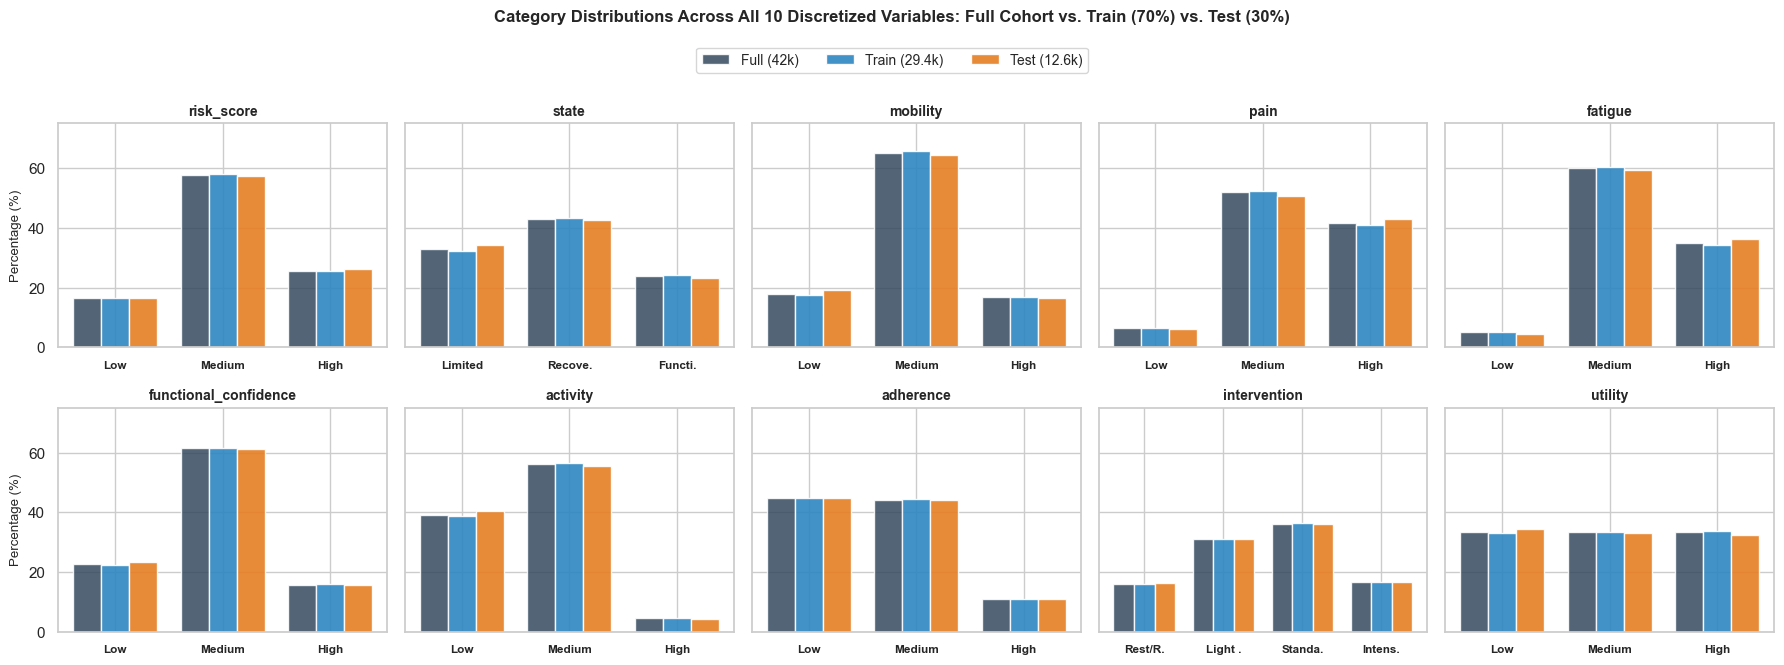

In [2]:
# Perform 70/30 split at the patient_id level
rng = np.random.default_rng(RANDOM_STATE)
unique_pids = np.sort(bn_full["patient_id"].unique())
shuffled_pids = rng.permutation(unique_pids)

n_train_patients = int(round(0.70 * len(unique_pids)))
train_pids = set(shuffled_pids[:n_train_patients])
test_pids = set(shuffled_pids[n_train_patients:])
assert len(train_pids & test_pids) == 0

train_df = bn_full[bn_full["patient_id"].isin(train_pids)][BN_VARS].reset_index(drop=True)
test_df = bn_full[bn_full["patient_id"].isin(test_pids)][BN_VARS].reset_index(drop=True)
full_df = bn_full[BN_VARS].reset_index(drop=True)

print(f"Train: {len(train_pids):,} patients ({len(train_df):,} rows, 70.0%) | Test: {len(test_pids):,} patients ({len(test_df):,} rows, 30.0%) | Patient overlap: {len(train_pids & test_pids)}")

# Plot 1: Visual comparison of category distributions across Full, Train, and Test splits
fig, axes = plt.subplots(2, 5, figsize=(18, 6.2), sharey=True)
axes = axes.flatten()

for idx, var in enumerate(BN_VARS):
    cats = STATE_NAMES[var]
    p_full = [(full_df[var] == c).mean() * 100 for c in cats]
    p_tr = [(train_df[var] == c).mean() * 100 for c in cats]
    p_te = [(test_df[var] == c).mean() * 100 for c in cats]
    
    x = np.arange(len(cats))
    w = 0.26
    axes[idx].bar(x - w, p_full, width=w, label="Full (42k)", color="#34495E", alpha=0.85)
    axes[idx].bar(x, p_tr, width=w, label="Train (29.4k)", color="#2E86C1", alpha=0.9)
    axes[idx].bar(x + w, p_te, width=w, label="Test (12.6k)", color="#E67E22", alpha=0.9)
    
    short_cats = [c[:6] + "." if len(c) > 7 else c for c in cats]
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(short_cats, fontsize=8.5, fontweight="bold")
    axes[idx].set_title(var, fontsize=10, fontweight="bold")
    axes[idx].set_ylim(0, 75)
    if idx % 5 == 0:
        axes[idx].set_ylabel("Percentage (%)", fontsize=9.5)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, fontsize=10, frameon=True, bbox_to_anchor=(0.5, 1.02))
plt.suptitle("Category Distributions Across All 10 Discretized Variables: Full Cohort vs. Train (70%) vs. Test (30%)", fontsize=12, fontweight="bold", y=1.07)
plt.tight_layout()
plt.show()

### 1.2 Parameter Estimation on the Hand-Designed M2 Structure

Using the 11-edge M2 network structure, we compare three CPT parameterizations:
1. **`M2_Full`:** Frequency counting on all $42{,}000$ rows (baseline from M2).
2. **`Train_MLE`:** Frequency counting on the $29{,}400$ training rows (`MaximumLikelihoodEstimator`).
3. **`Train_BDeu`:** Bayesian Dirichlet smoothing on the $29{,}400$ training rows (`BayesianEstimator` with `prior_type="BDeu"`, `equivalent_sample_size=10`, plus sensitivity across $\text{ESS} \in \{1, 5, 10, 50\}$).

,Node,Parents,CPT Cells,Max |M2_Full - Train_MLE|,Mean |M2_Full - Train_MLE|,Max |Train_MLE - Train_BDeu|,Zero Cells (MLE / BDeu)
0,risk_score,(Root),3,0.0018,0.0012,0.0001,0 / 0
1,state,risk_score,9,0.0118,0.0050,0.0002,0 / 0
2,mobility,state,9,0.0092,0.0034,0.0002,0 / 0
3,pain,state,9,0.0043,0.0018,0.0002,0 / 0
4,fatigue,state,9,0.0081,0.0028,0.0002,0 / 0
5,functional_confidence,state,9,0.0027,0.0012,0.0002,0 / 0
6,activity,state,9,0.0048,0.0022,0.0002,1 / 0
7,adherence,state,9,0.0070,0.0024,0.0001,0 / 0
8,intervention,state,12,0.0050,0.0017,0.0001,0 / 0
9,utility,"adherence, intervention, state",108,0.0397,0.0066,0.0015,1 / 0


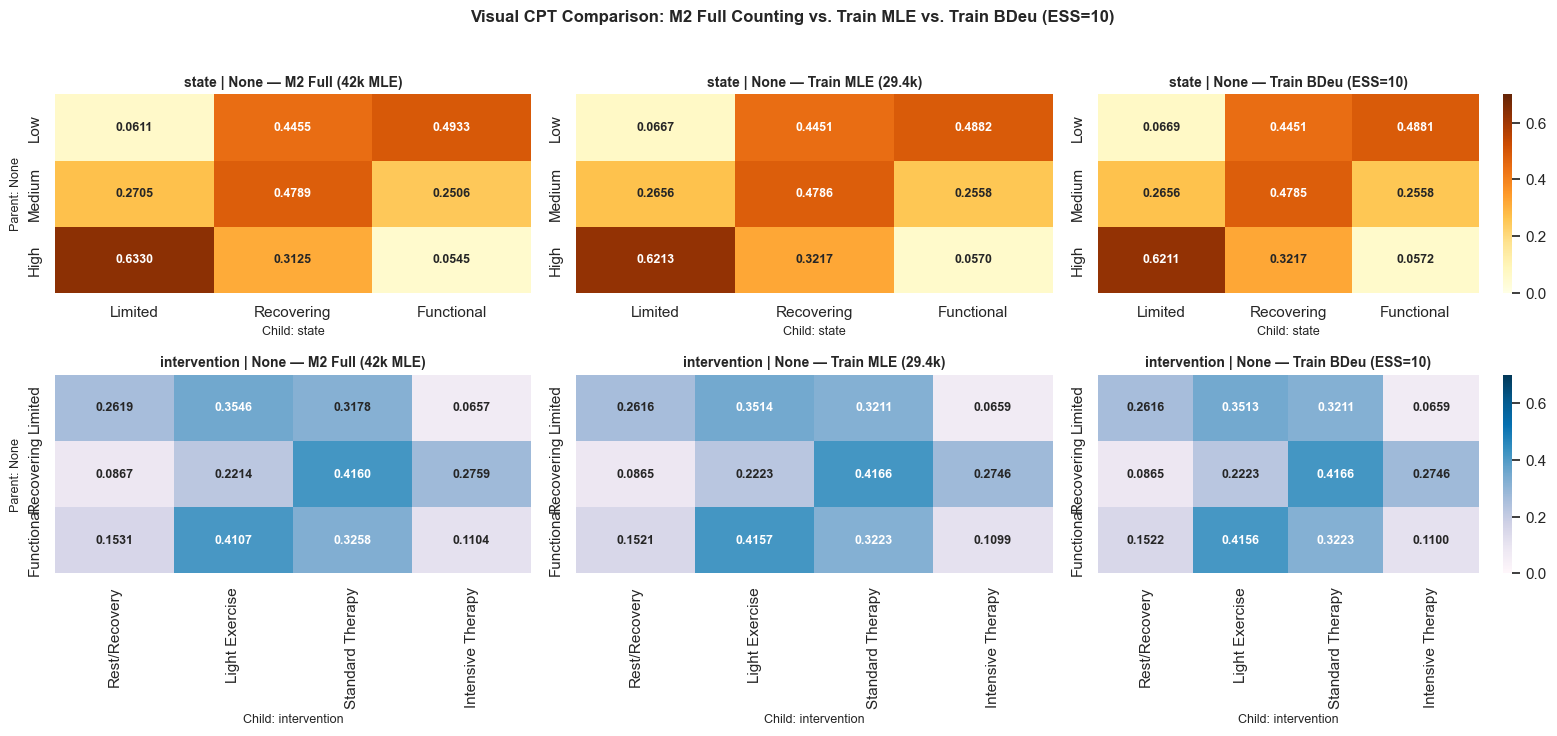

In [3]:
def build_and_fit_bn(edges, df, estimator="bdeu", ess=10):
    model = DiscreteBayesianNetwork(list(edges))
    model.add_nodes_from(BN_VARS)
    if estimator == "mle":
        cpds = MaximumLikelihoodEstimator(model, df, state_names=STATE_NAMES).get_parameters()
    elif estimator == "bdeu":
        cpds = BayesianEstimator(model, df, state_names=STATE_NAMES).get_parameters(prior_type="BDeu", equivalent_sample_size=ess)
    else:
        raise ValueError(f"Unknown estimator: {estimator}")
    model.add_cpds(*cpds)
    assert model.check_model()
    return model

def count_free_parameters(model):
    total = 0
    for cpd in model.get_cpds():
        r = len(cpd.state_names[cpd.variable])
        parents = cpd.variables[1:]
        q = int(np.prod([len(cpd.state_names[p]) for p in parents])) if parents else 1
        total += (r - 1) * q
    return total

def cpd_to_dataframe(model, var):
    cpd = model.get_cpds(var)
    vals = cpd.get_values()
    parents = cpd.variables[1:]
    row_states = cpd.state_names[var]
    if not parents:
        return pd.DataFrame(vals.T, index=["Prior"], columns=row_states)
    parent_states = [cpd.state_names[p] for p in parents]
    idx = pd.MultiIndex.from_product(parent_states, names=parents)
    return pd.DataFrame(vals.T, index=idx, columns=row_states)

m2_full_mle = build_and_fit_bn(M2_EDGES, full_df, estimator="mle")
hand_train_mle = build_and_fit_bn(M2_EDGES, train_df, estimator="mle")
hand_train_bdeu = build_and_fit_bn(M2_EDGES, train_df, estimator="bdeu", ess=10)

node_diff_rows = []
for var in BN_VARS:
    df_m2 = cpd_to_dataframe(m2_full_mle, var)
    df_mle = cpd_to_dataframe(hand_train_mle, var)
    df_bd = cpd_to_dataframe(hand_train_bdeu, var)
    parents = hand_train_mle.get_cpds(var).variables[1:]
    node_diff_rows.append({
        "Node": var,
        "Parents": ", ".join(parents) if parents else "(Root)",
        "CPT Cells": df_mle.values.size,
        "Max |M2_Full - Train_MLE|": np.abs(df_m2.values - df_mle.values).max(),
        "Mean |M2_Full - Train_MLE|": np.abs(df_m2.values - df_mle.values).mean(),
        "Max |Train_MLE - Train_BDeu|": np.abs(df_mle.values - df_bd.values).max(),
        "Zero Cells (MLE / BDeu)": f"{int((df_mle.values == 0).sum())} / {int((df_bd.values == 0).sum())}",
    })

display(pd.DataFrame(node_diff_rows))

# Plot 2: Visual CPT Heatmaps for 'state | risk_score' and 'intervention | state'
fig, axes = plt.subplots(2, 3, figsize=(16, 7.2))

for row_i, (var, cmap) in enumerate([("state", "YlOrBr"), ("intervention", "PuBu")]):
    for col_i, (title_tag, mod) in enumerate([
        ("M2 Full (42k MLE)", m2_full_mle),
        ("Train MLE (29.4k)", hand_train_mle),
        ("Train BDeu (ESS=10)", hand_train_bdeu),
    ]):
        df_c = cpd_to_dataframe(mod, var)
        sns.heatmap(
            df_c, annot=True, fmt=".4f", cmap=cmap, vmin=0, vmax=0.70,
            cbar=(col_i == 2), ax=axes[row_i, col_i], annot_kws={"size": 9, "weight": "bold"}
        )
        axes[row_i, col_i].set_title(f"{var} | {df_c.index.name} — {title_tag}", fontsize=10, fontweight="bold")
        axes[row_i, col_i].set_xlabel(f"Child: {var}", fontsize=9)
        axes[row_i, col_i].set_ylabel(f"Parent: {df_c.index.name}" if col_i == 0 else "", fontsize=9)

plt.suptitle("Visual CPT Comparison: M2 Full Counting vs. Train MLE vs. Train BDeu (ESS=10)", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 1.3 Rare Parent Configurations & Zero-Count Smoothing in `utility` and `activity`

Below we examine the 36 parent combinations of `utility | state, intervention, adherence` and visualize how small sample sizes ($N_{ij}$) increase estimation noise and create zero-probability cells in `Train_MLE`, which `BDeu` smoothing resolves.

=== 6 Rarest Parent Configurations in 'utility | adherence, intervention, state' ===


N_Full  N_Train  M2_Low  MLE_Low  BDeu10_Low  M2_Medium  MLE_Medium  BDeu10_Medium  M2_High  MLE_High  BDeu10_High  Max |M2 - MLE|  Max |MLE - BDeu10|  \
adherence intervention      state                                                                                                                                                                
High      Intensive Therapy Limited         94       71  0.7021   0.6761      0.6747     0.2766      0.2958         0.2959   0.0213    0.0282       0.0294          0.0261              0.0013   
                            Functional     151      115  0.0199   0.0174      0.0182     0.1722      0.1652         0.1656   0.8079    0.8174       0.8162          0.0094              0.0012   
          Rest/Recovery     Functional     175      116  0.0057   0.0000      0.0008     0.0857      0.0517         0.0524   0.9086    0.9483       0.9468          0.0397              0.0015   
                            Recovering     190      138  0.1053   0.1232      0.1236     0.3895      0.3768         0.3767   0.5053    0.5000       0.4997          0.0179              0.0004   
                            Limited        305      203  0.5672   0.5567      0.5563     0.3639      0.3596         0.3596   0.0689    0.0837       0.0841          0.0149              0.0003   
Medium    Intensive Therapy Limited        364      246  0.7582   0.7276      0.7272     0.2198      0.2439         0.2440   0.0220    0.0285       0.0288          0.0306              0.0004   

                                        Max |MLE - BDeu50|  
adherence intervention      state                           
High      Intensive Therapy Limited                 0.0066  
                            Functional              0.0058  
          Rest/Recovery     Functional              0.0073  
                            Recovering              0.0021  
                            Limited                 0.0017  
Medium    Intensive Therapy Limited                 0.0022

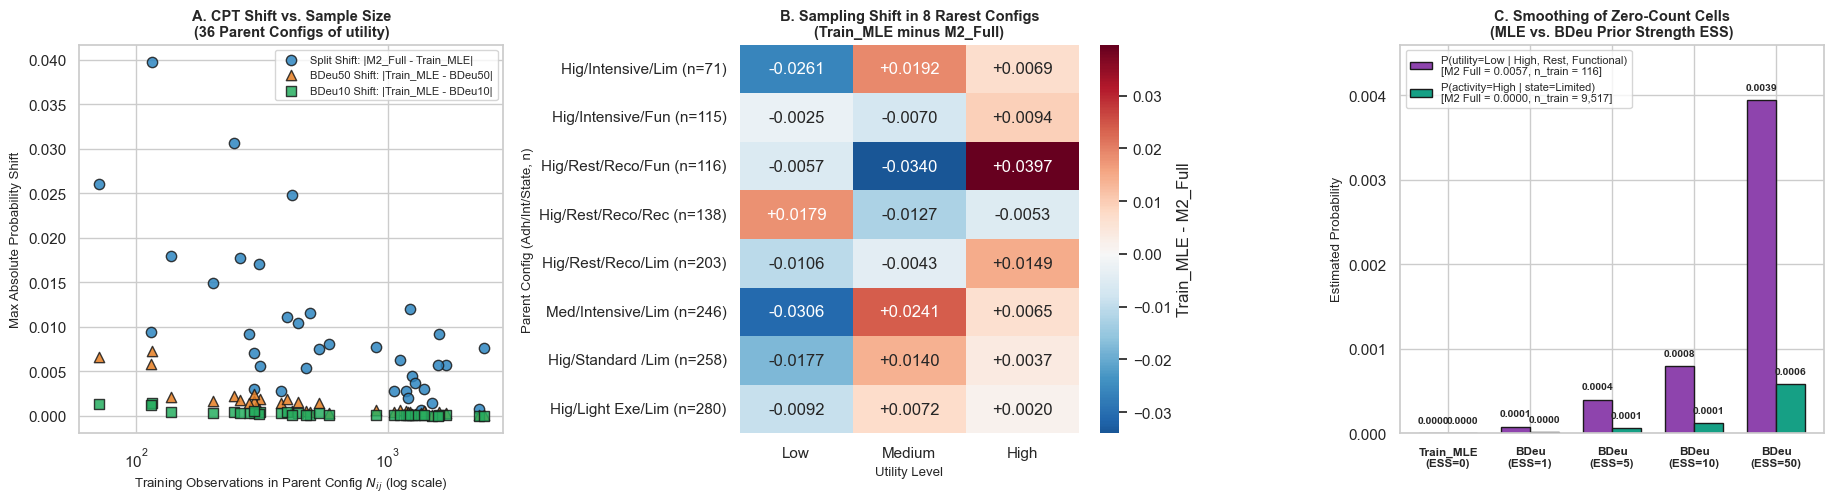

In [4]:
u_m2 = cpd_to_dataframe(m2_full_mle, "utility")
u_mle = cpd_to_dataframe(hand_train_mle, "utility")
u_bd10 = cpd_to_dataframe(hand_train_bdeu, "utility")
u_bd50 = cpd_to_dataframe(build_and_fit_bn(M2_EDGES, train_df, "bdeu", ess=50), "utility")

parent_cols = list(u_mle.index.names)
train_counts = train_df.groupby(parent_cols).size().reindex(u_mle.index, fill_value=0)
full_counts = full_df.groupby(parent_cols).size().reindex(u_mle.index, fill_value=0)

utility_comp = pd.DataFrame(index=u_mle.index)
utility_comp["N_Full"] = full_counts
utility_comp["N_Train"] = train_counts
for st in LEVEL_ORDER:
    utility_comp[f"M2_{st}"] = u_m2[st]
    utility_comp[f"MLE_{st}"] = u_mle[st]
    utility_comp[f"BDeu10_{st}"] = u_bd10[st]
utility_comp["Max |M2 - MLE|"] = np.abs(u_m2.values - u_mle.values).max(axis=1)
utility_comp["Max |MLE - BDeu10|"] = np.abs(u_mle.values - u_bd10.values).max(axis=1)
utility_comp["Max |MLE - BDeu50|"] = np.abs(u_mle.values - u_bd50.values).max(axis=1)

print("=== 6 Rarest Parent Configurations in 'utility | adherence, intervention, state' ===")
display(utility_comp.sort_values("N_Train").head(6))

# Plot 3: 3-Panel Visual Analysis of Rare Configurations & BDeu Zero-Cell Smoothing
fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.2))

# Panel A: Sample Size vs CPT Shift
axes[0].scatter(utility_comp["N_Train"], utility_comp["Max |M2 - MLE|"], label="Split Shift: |M2_Full - Train_MLE|", color="#2E86C1", s=55, edgecolor="k", alpha=0.85)
axes[0].scatter(utility_comp["N_Train"], utility_comp["Max |MLE - BDeu50|"], label="BDeu50 Shift: |Train_MLE - BDeu50|", color="#E67E22", marker="^", s=55, edgecolor="k", alpha=0.85)
axes[0].scatter(utility_comp["N_Train"], utility_comp["Max |MLE - BDeu10|"], label="BDeu10 Shift: |Train_MLE - BDeu10|", color="#27AE60", marker="s", s=50, edgecolor="k", alpha=0.85)
axes[0].set_xscale("log")
axes[0].set_xlabel("Training Observations in Parent Config $N_{ij}$ (log scale)", fontsize=9.5)
axes[0].set_ylabel("Max Absolute Probability Shift", fontsize=9.5)
axes[0].set_title("A. CPT Shift vs. Sample Size\n(36 Parent Configs of utility)", fontsize=10.5, fontweight="bold")
axes[0].legend(fontsize=8, frameon=True)

# Panel B: Heatmap of Probability Shifts in 8 Rarest Configs
rarest8_idx = utility_comp.sort_values("N_Train").head(8).index
diff_rarest8 = (u_mle.loc[rarest8_idx] - u_m2.loc[rarest8_idx]).copy()
diff_rarest8.index = [f"{i[0][:3]}/{i[1][:9]}/{i[2][:3]} (n={train_counts.loc[i]})" for i in rarest8_idx]
sns.heatmap(diff_rarest8, annot=True, fmt="+.4f", cmap="RdBu_r", center=0, ax=axes[1], cbar_kws={"label": "Train_MLE - M2_Full"})
axes[1].set_title("B. Sampling Shift in 8 Rarest Configs\n(Train_MLE minus M2_Full)", fontsize=10.5, fontweight="bold")
axes[1].set_xlabel("Utility Level", fontsize=9.5)
axes[1].set_ylabel("Parent Config (Adh/Int/State, n)", fontsize=9.5)

# Panel C: How BDeu Lifts the Two Zero-Count Cells Across ESS
ess_labels = ["Train_MLE\n(ESS=0)", "BDeu\n(ESS=1)", "BDeu\n(ESS=5)", "BDeu\n(ESS=10)", "BDeu\n(ESS=50)"]
ess_models = [hand_train_mle] + [build_and_fit_bn(M2_EDGES, train_df, "bdeu", ess=e) for e in [1, 5, 10, 50]]
cell_util_zero = [float(cpd_to_dataframe(m, "utility").loc[("High", "Rest/Recovery", "Functional"), "Low"]) for m in ess_models]
cell_act_zero = [float(cpd_to_dataframe(m, "activity").loc[("Limited",), "High"]) for m in ess_models]

x_e = np.arange(len(ess_labels))
w_e = 0.35
b_u = axes[2].bar(x_e - w_e/2, cell_util_zero, w_e, label="P(utility=Low | High, Rest, Functional)\n[M2 Full = 0.0057, n_train = 116]", color="#8E44AD", edgecolor="k")
b_a = axes[2].bar(x_e + w_e/2, cell_act_zero, w_e, label="P(activity=High | state=Limited)\n[M2 Full = 0.0000, n_train = 9,517]", color="#16A085", edgecolor="k")
for bar in list(b_u) + list(b_a):
    val = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, val + 0.0001, f"{val:.4f}", ha="center", va="bottom", fontsize=7.5, fontweight="bold")
axes[2].set_xticks(x_e)
axes[2].set_xticklabels(ess_labels, fontsize=8.5, fontweight="bold")
axes[2].set_ylim(0, 0.0046)
axes[2].set_ylabel("Estimated Probability", fontsize=9.5)
axes[2].set_title("C. Smoothing of Zero-Count Cells\n(MLE vs. BDeu Prior Strength ESS)", fontsize=10.5, fontweight="bold")
axes[2].legend(fontsize=8, frameon=True)

plt.tight_layout()
plt.show()

### 1.4 Summary of Task 1 Findings

* **Similar probabilities on common states:** Nodes with 0 or 1 parent have thousands of rows per condition, so `Train_MLE` is almost identical to M2 ($\max|\Delta| \le 0.0118$ in `state` and $0.0050$ in `intervention`, **Plot 2**).
* **Larger shifts and zero counts on rare configurations:** Splitting `utility` across 36 parent combinations leaves as few as **$n = 71$** rows for `(High, Intensive Therapy, Limited)` and **$n = 116$** for `(High, Rest/Recovery, Functional)`. Smaller counts cause larger probability shifts (up to **$0.0397$**, **Plot 3A–B**) and produce **2 exact zeros** in `Train_MLE` (`P(activity=High | Limited) = 0` and `P(utility=Low | High, Rest, Functional) = 0`), which cause $\log(0) = -\infty$ on unseen test data.
* **Effect of Bayesian estimation (`BDeu`):** Adding a small virtual count ($	ext{ESS}=10$) barely touches dense rows ($\le 0.0002$), gently smooths sparse rows ($\le 0.0015$), and lifts zero cells to small positive values ($0.0008$ and $0.0001$, **Plot 3C**).

---
## Task 2: Structure Learning

### 2.1 Unconstrained Score-Based Search (`HillClimbSearch`)

We run greedy **Hill-Climbing Search (`HillClimbSearch`)** on the $29{,}400$ training rows with no constraints, comparing `BIC` (`bic-d`, primary) against `BDeu` and `K2`.

,Scoring Method,Learned Edges,Max In-Degree,Free Params (k),Train BIC,Test BIC
0,"BIC (bic-d, Primary)",19,3,233,-231625.4292,-98868.0431
1,BDeu (ess=10),22,3,341,-231727.1903,-99146.2507
2,K2 Score,29,9,52883,-498572.5109,-344870.2497


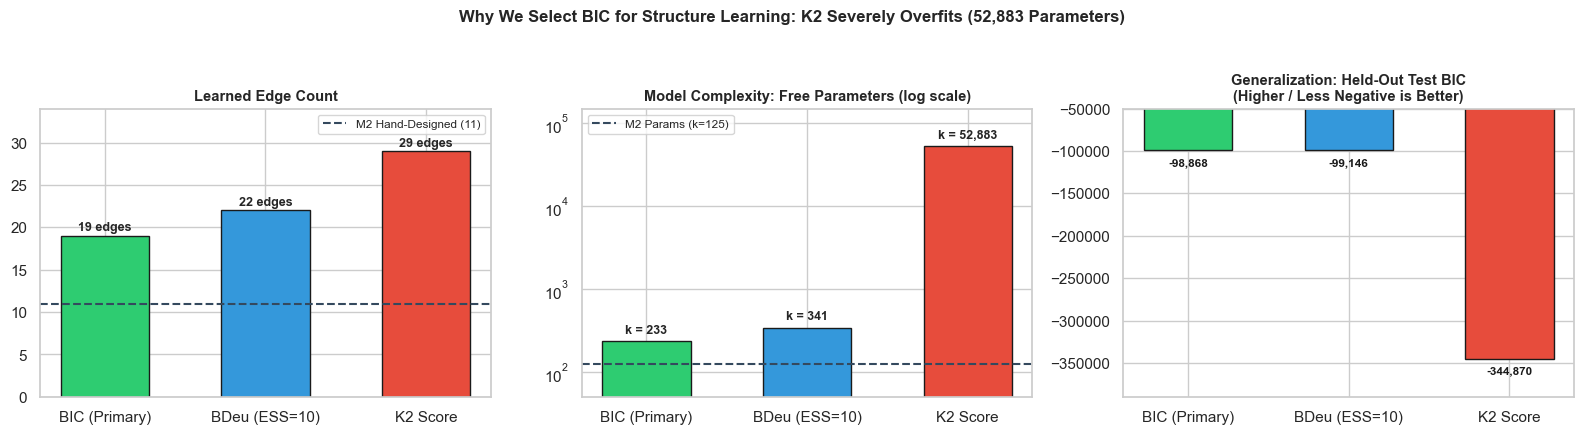

In [5]:
# Ensure 100% deterministic tie-breaking in HillClimbSearch across Python hash seeds
_orig_legal_ops = HillClimbSearch._legal_operations
HillClimbSearch._legal_operations = lambda self, *a, **kw: sorted(
    _orig_legal_ops(self, *a, **kw),
    key=lambda x: (x[0][0], BN_VARS.index(x[0][1][0]), BN_VARS.index(x[0][1][1])),
)

hc_search = HillClimbSearch(train_df)

t0 = time.perf_counter()
learned_dag_bic = hc_search.estimate(scoring_method="bic-d", show_progress=False)
bic_runtime = time.perf_counter() - t0

learned_dag_bdeu = hc_search.estimate(scoring_method="bdeu", show_progress=False)
learned_dag_k2 = hc_search.estimate(scoring_method="k2", show_progress=False)

bic_train_scorer = BIC(train_df)
bic_test_scorer = BIC(test_df)

score_comp_rows = []
for name, dag in [("BIC (bic-d, Primary)", learned_dag_bic), ("BDeu (ess=10)", learned_dag_bdeu), ("K2 Score", learned_dag_k2)]:
    fitted = build_and_fit_bn(dag.edges(), train_df, estimator="bdeu", ess=10)
    in_degrees = [len(fitted.get_cpds(v).variables[1:]) for v in BN_VARS]
    score_comp_rows.append({
        "Scoring Method": name,
        "Learned Edges": len(dag.edges()),
        "Max In-Degree": max(in_degrees),
        "Free Params (k)": count_free_parameters(fitted),
        "Train BIC": bic_train_scorer.score(fitted),
        "Test BIC": bic_test_scorer.score(fitted),
    })

score_comp_df = pd.DataFrame(score_comp_rows)
display(score_comp_df)

# Plot 4: Visual Comparison of Structure Scoring Methods (BIC vs BDeu vs K2)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
methods_short = ["BIC (Primary)", "BDeu (ESS=10)", "K2 Score"]
cols_m = ["#2ECC71", "#3498DB", "#E74C3C"]

# Panel 1: Number of Learned Edges
b_e = axes[0].bar(methods_short, score_comp_df["Learned Edges"], color=cols_m, edgecolor="k", width=0.55)
for bar in b_e:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.6, f"{int(bar.get_height())} edges", ha="center", fontweight="bold", fontsize=9)
axes[0].axhline(len(M2_EDGES), color="#34495E", ls="--", lw=1.5, label=f"M2 Hand-Designed ({len(M2_EDGES)})")
axes[0].set_ylim(0, 34)
axes[0].set_title("Learned Edge Count", fontsize=10.5, fontweight="bold")
axes[0].legend(fontsize=8.5)

# Panel 2: Free Parameters (log scale)
b_p = axes[1].bar(methods_short, score_comp_df["Free Params (k)"], color=cols_m, edgecolor="k", width=0.55)
axes[1].set_yscale("log")
for bar in b_p:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.25, f"k = {int(bar.get_height()):,}", ha="center", fontweight="bold", fontsize=9)
axes[1].axhline(125, color="#34495E", ls="--", lw=1.5, label="M2 Params (k=125)")
axes[1].set_ylim(50, 150000)
axes[1].set_title("Model Complexity: Free Parameters (log scale)", fontsize=10.5, fontweight="bold")
axes[1].legend(fontsize=8.5)

# Panel 3: Held-Out Test BIC
b_t = axes[2].bar(methods_short, score_comp_df["Test BIC"], color=cols_m, edgecolor="k", width=0.55)
for bar in b_t:
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() - 18000, f"{bar.get_height():,.0f}", ha="center", fontweight="bold", fontsize=8.5, color="k")
axes[2].set_ylim(-390000, -50000)
axes[2].set_title("Generalization: Held-Out Test BIC\n(Higher / Less Negative is Better)", fontsize=10.5, fontweight="bold")

plt.suptitle("Why We Select BIC for Structure Learning: K2 Severely Overfits (52,883 Parameters)", fontsize=12, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### 2.2 Visualizing Hand-Designed (M2) vs. Learned (BIC) Topologies

Below we visualize both networks side-by-side (**Plot 5**) and compare their adjacency matrices and node degrees (**Plot 6**).

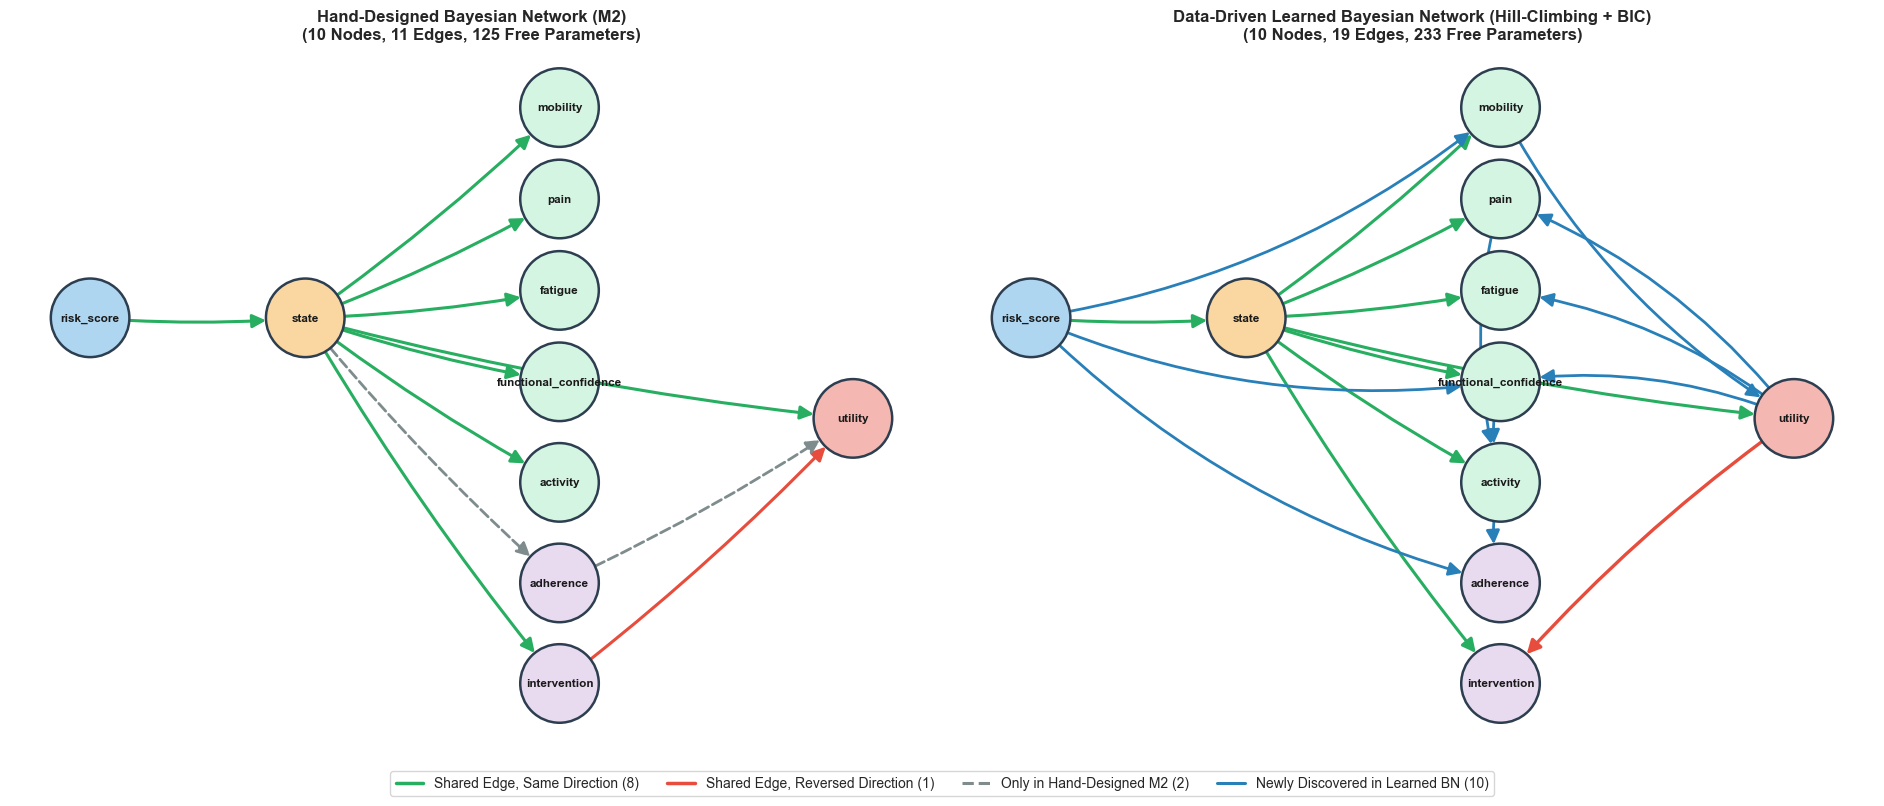

In [6]:
hand_edge_set = set(M2_EDGES)
learned_edge_set = set(learned_dag_bic.edges())

shared_same_dir = sorted(hand_edge_set & learned_edge_set)
shared_reversed = sorted([(u, v) for (u, v) in learned_edge_set if (v, u) in hand_edge_set])
only_in_hand = sorted([(u, v) for (u, v) in hand_edge_set if (u, v) not in learned_edge_set and (v, u) not in learned_edge_set])
only_in_learned = sorted([(u, v) for (u, v) in learned_edge_set if (u, v) not in hand_edge_set and (v, u) not in hand_edge_set])

cpdag = learned_dag_bic.to_pdag()
compelled_edges = sorted(cpdag.directed_edges)
reversible_pairs = sorted({tuple(sorted(e)) for e in cpdag.undirected_edges})

# Plot 5: Side-by-side DAG Visualization of Hand-Designed (M2) vs. Learned (BIC)
pos = {
    "risk_score": (0.4, 2.3),
    "state": (2.6, 2.3),
    "mobility": (5.2, 4.6),
    "pain": (5.2, 3.6),
    "fatigue": (5.2, 2.6),
    "functional_confidence": (5.2, 1.6),
    "activity": (5.2, 0.5),
    "adherence": (5.2, -0.6),
    "intervention": (5.2, -1.7),
    "utility": (8.2, 1.2),
}

def get_node_color(node):
    if node == "risk_score":
        return "#AED6F1"
    elif node == "state":
        return "#FAD7A0"
    elif node in ["mobility", "pain", "fatigue", "functional_confidence", "activity"]:
        return "#D5F5E3"
    elif node in ["adherence", "intervention"]:
        return "#E8DAEF"
    return "#F5B7B1"

fig, axes = plt.subplots(1, 2, figsize=(19, 8.2))

G_hand = nx.DiGraph()
G_hand.add_nodes_from(BN_VARS)
G_hand.add_edges_from(M2_EDGES)

nx.draw_networkx_nodes(G_hand, pos, ax=axes[0], node_color=[get_node_color(n) for n in G_hand.nodes()], node_size=3200, edgecolors="#2C3E50", linewidths=1.8)
nx.draw_networkx_labels(G_hand, pos, ax=axes[0], font_size=8.5, font_weight="bold")
nx.draw_networkx_edges(G_hand, pos, edgelist=shared_same_dir, ax=axes[0], arrows=True, arrowsize=20, edge_color="#27AE60", width=2.2, connectionstyle="arc3,rad=0.04", node_size=3200)
nx.draw_networkx_edges(G_hand, pos, edgelist=[(v, u) for (u, v) in shared_reversed], ax=axes[0], arrows=True, arrowsize=20, edge_color="#E74C3C", width=2.2, connectionstyle="arc3,rad=0.04", node_size=3200)
nx.draw_networkx_edges(G_hand, pos, edgelist=only_in_hand, ax=axes[0], arrows=True, arrowsize=20, edge_color="#7F8C8D", style="dashed", width=2.0, connectionstyle="arc3,rad=0.04", node_size=3200)
axes[0].set_title("Hand-Designed Bayesian Network (M2)\n(10 Nodes, 11 Edges, 125 Free Parameters)", fontsize=12, fontweight="bold")
axes[0].axis("off")

G_learned = nx.DiGraph()
G_learned.add_nodes_from(BN_VARS)
G_learned.add_edges_from(learned_dag_bic.edges())

nx.draw_networkx_nodes(G_learned, pos, ax=axes[1], node_color=[get_node_color(n) for n in G_learned.nodes()], node_size=3200, edgecolors="#2C3E50", linewidths=1.8)
nx.draw_networkx_labels(G_learned, pos, ax=axes[1], font_size=8.5, font_weight="bold")
nx.draw_networkx_edges(G_learned, pos, edgelist=shared_same_dir, ax=axes[1], arrows=True, arrowsize=20, edge_color="#27AE60", width=2.2, connectionstyle="arc3,rad=0.04", node_size=3200)
nx.draw_networkx_edges(G_learned, pos, edgelist=shared_reversed, ax=axes[1], arrows=True, arrowsize=20, edge_color="#E74C3C", width=2.4, connectionstyle="arc3,rad=0.06", node_size=3200)
nx.draw_networkx_edges(G_learned, pos, edgelist=only_in_learned, ax=axes[1], arrows=True, arrowsize=20, edge_color="#2980B9", width=2.0, connectionstyle="arc3,rad=0.14", node_size=3200)
axes[1].set_title("Data-Driven Learned Bayesian Network (Hill-Climbing + BIC)\n(10 Nodes, 19 Edges, 233 Free Parameters)", fontsize=12, fontweight="bold")
axes[1].axis("off")

legend_items = [
    plt.Line2D([0], [0], color="#27AE60", lw=2.5, label=f"Shared Edge, Same Direction ({len(shared_same_dir)})"),
    plt.Line2D([0], [0], color="#E74C3C", lw=2.5, label=f"Shared Edge, Reversed Direction ({len(shared_reversed)})"),
    plt.Line2D([0], [0], color="#7F8C8D", lw=2.2, ls="--", label=f"Only in Hand-Designed M2 ({len(only_in_hand)})"),
    plt.Line2D([0], [0], color="#2980B9", lw=2.2, label=f"Newly Discovered in Learned BN ({len(only_in_learned)})"),
]
fig.legend(handles=legend_items, loc="lower center", ncol=4, fontsize=10, frameon=True, bbox_to_anchor=(0.5, 0.01))
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

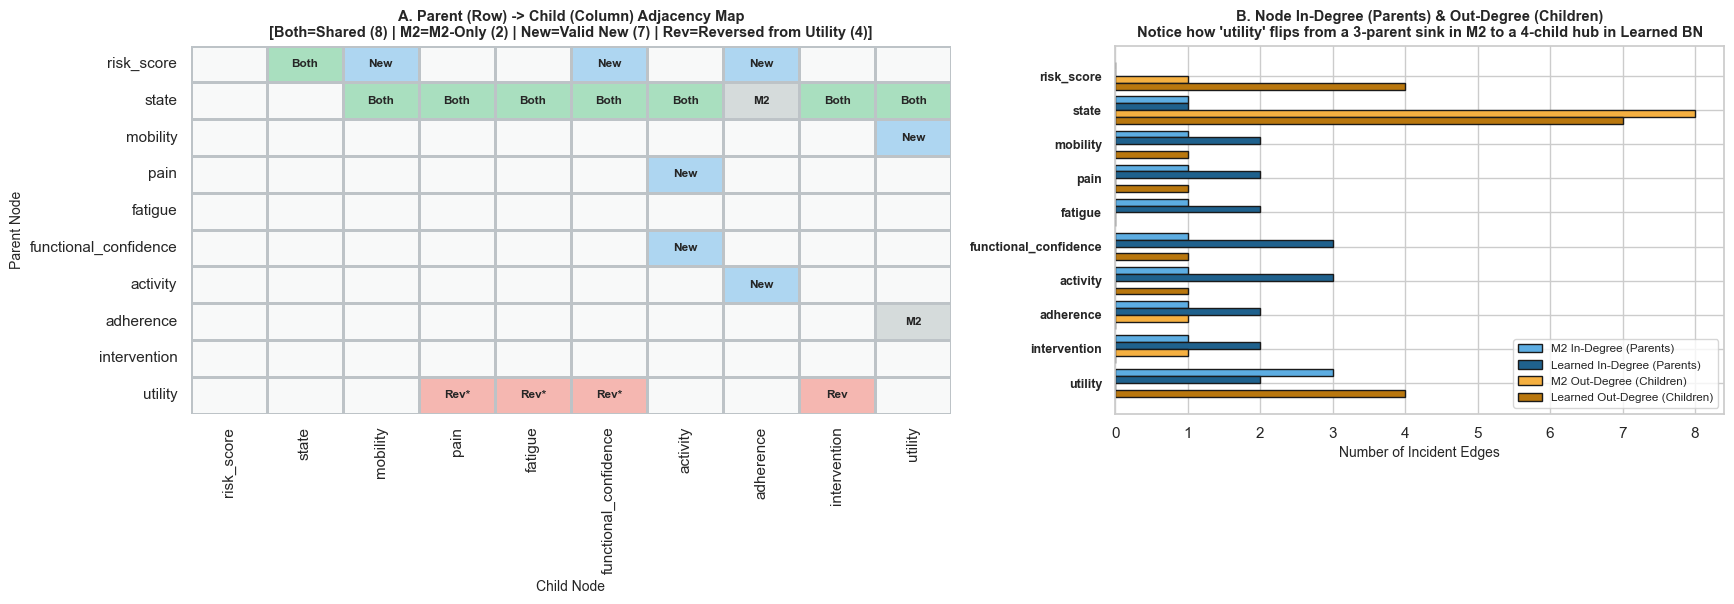

In [7]:
# Plot 6: Adjacency Matrix Edge-Diff Heatmap & Node Degree Comparison
adj_status = pd.DataFrame(0, index=BN_VARS, columns=BN_VARS)
annot_mat = pd.DataFrame("", index=BN_VARS, columns=BN_VARS)

for u, v in shared_same_dir:
    adj_status.loc[u, v] = 1
    annot_mat.loc[u, v] = "Both"
for u, v in only_in_hand:
    adj_status.loc[u, v] = 2
    annot_mat.loc[u, v] = "M2"
for u, v in only_in_learned:
    # Mark clinically plausible new edges as 3, reversed outcome edges from utility as 4
    if u == "utility":
        adj_status.loc[u, v] = 4
        annot_mat.loc[u, v] = "Rev*"
    else:
        adj_status.loc[u, v] = 3
        annot_mat.loc[u, v] = "New"
for u, v in shared_reversed:
    adj_status.loc[u, v] = 4
    annot_mat.loc[u, v] = "Rev"

fig, axes = plt.subplots(1, 2, figsize=(17.5, 6.2), gridspec_kw={"width_ratios": [1.25, 1.0]})

from matplotlib.colors import ListedColormap
cmap_adj = ListedColormap(["#F8F9F9", "#A9DFBF", "#D5DBDB", "#AED6F1", "#F5B7B1"])
sns.heatmap(
    adj_status, annot=annot_mat, fmt="", cmap=cmap_adj, cbar=False,
    linewidths=1, linecolor="#BDC3C7", ax=axes[0], annot_kws={"size": 8.5, "weight": "bold"}
)
axes[0].set_title("A. Parent (Row) -> Child (Column) Adjacency Map\n[Both=Shared (8) | M2=M2-Only (2) | New=Valid New (7) | Rev=Reversed from Utility (4)]", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("Child Node", fontsize=10)
axes[0].set_ylabel("Parent Node", fontsize=10)

# Right panel: Node In-Degree + Out-Degree comparison
y_pos = np.arange(len(BN_VARS))
h_in = [G_hand.in_degree(n) for n in BN_VARS]
l_in = [G_learned.in_degree(n) for n in BN_VARS]
h_out = [G_hand.out_degree(n) for n in BN_VARS]
l_out = [G_learned.out_degree(n) for n in BN_VARS]

w_d = 0.2
axes[1].barh(y_pos - 1.5*w_d, h_in, height=w_d, label="M2 In-Degree (Parents)", color="#5DADE2", edgecolor="k")
axes[1].barh(y_pos - 0.5*w_d, l_in, height=w_d, label="Learned In-Degree (Parents)", color="#1F618D", edgecolor="k")
axes[1].barh(y_pos + 0.5*w_d, h_out, height=w_d, label="M2 Out-Degree (Children)", color="#F5B041", edgecolor="k")
axes[1].barh(y_pos + 1.5*w_d, l_out, height=w_d, label="Learned Out-Degree (Children)", color="#B9770E", edgecolor="k")

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(BN_VARS, fontsize=9, fontweight="bold")
axes[1].invert_yaxis()
axes[1].set_xlabel("Number of Incident Edges", fontsize=10)
axes[1].set_title("B. Node In-Degree (Parents) & Out-Degree (Children)\nNotice how 'utility' flips from a 3-parent sink in M2 to a 4-child hub in Learned BN", fontsize=10.5, fontweight="bold")
axes[1].legend(fontsize=8.5, frameon=True)

plt.tight_layout()
plt.show()

### 2.3 Structural Comparison & Domain Critique

| Category | Count | Edges | Clinical Interpretation |
| :--- | :---: | :--- | :--- |
| **In Both (Same Direction)** | **8** | `risk_score -> state` and `state -> {mobility, pain, fatigue, functional_confidence, activity, intervention, utility}` | Confirms M2's core structure: `risk_score` drives `state`, and `state` acts as the central hub. |
| **In Both (Opposite Direction)** | **1** | `utility -> intervention` (vs. M2 `intervention -> utility`) | Captures therapy–outcome correlation, but reverses cause and effect. |
| **Only in M2** | **2** | `state -> adherence`, `adherence -> utility` | Replaced in the learned graph by `state -> activity -> adherence` and `risk_score -> adherence`. |
| **Only in Learned BN** | **10** | **7 clinically valid:** `risk_score -> {mobility, functional_confidence, adherence}`, `pain -> activity`, `functional_confidence -> activity`, `activity -> adherence`, `mobility -> utility`<br>**3 reversed:** `utility -> {pain, fatigue, functional_confidence}` | 7 capture real symptom/risk links beyond coarse 3-level `state`; 3 point backwards from outcome `utility` into symptoms. |

* **Why did `BIC` reverse the 4 edges around `utility`?** As shown in **Plot 6B**, pointing 6 variables *into* `utility` would create a 6-parent table ($972$ parent rows, $1{,}944$ parameters) with a huge BIC complexity penalty. Flipping `utility` to point *out* into `pain`, `fatigue`, `functional_confidence`, and `intervention` keeps every node at $\le 3$ parents ($233$ total parameters) while capturing the same correlations.

---
## Task 3: Model Comparison on Held-Out Test Data

We evaluate both networks on the $12{,}600$ unseen test rows ($900$ test patients) using **Test BIC** (primary criterion) and **Held-Out Log-Likelihood**.

,Model & Estimator,Edges,Params (k),SHD vs. M2,Train LL,Test LL,Test LL / Obs,Test -inf Rows,Train BIC,Test BIC (Primary)
0,Hand-Designed BN (M2) — BDeu (ESS=10),11,125,0,-236166.3654,-100570.2293,-7.9818,0,-236806.9342,-101038.4872
1,Learned BN (BIC) — BDeu (ESS=10),19,233,13,-230432.3776,-97985.8655,-7.7767,0,-231625.4292,-98868.0431
2,Hand-Designed BN (M2) — Pure MLE,11,125,0,-236163.8873,-inf,-inf,1,-236806.9342,-101038.4872
3,Learned BN (BIC) — Pure MLE,19,233,13,-230426.7898,-inf,-inf,4,-231625.4292,-98868.0431


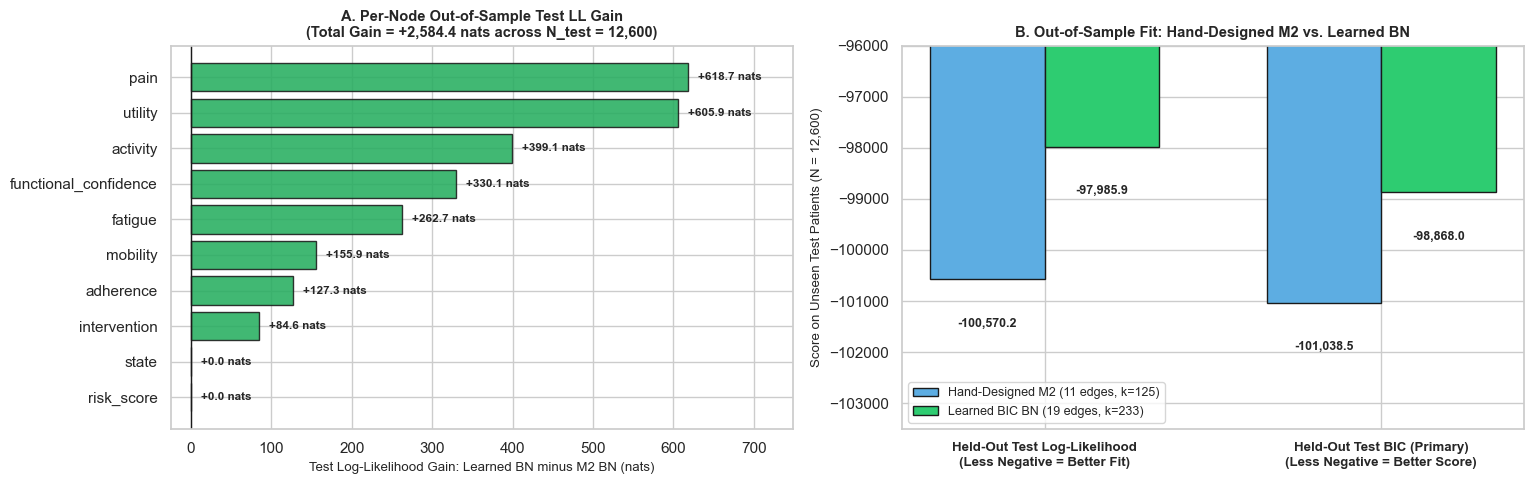

In [8]:
def evaluate_log_likelihood(model, df):
    n_obs = len(df)
    total_ll = np.zeros(n_obs, dtype=float)
    per_node_ll = {}
    for var in BN_VARS:
        cpd = model.get_cpds(var)
        vals = cpd.get_values()
        parents = cpd.variables[1:]
        row_idx = df[var].map({s: i for i, s in enumerate(cpd.state_names[var])}).values
        if parents:
            col_idx = np.zeros(n_obs, dtype=int)
            stride = 1
            for p in reversed(parents):
                p_idx = df[p].map({s: i for i, s in enumerate(cpd.state_names[p])}).values
                col_idx += p_idx * stride
                stride *= len(cpd.state_names[p])
        else:
            col_idx = np.zeros(n_obs, dtype=int)
        with np.errstate(divide="ignore"):
            node_ll = np.log(vals[row_idx, col_idx])
        per_node_ll[var] = node_ll
        total_ll += node_ll
    return total_ll, per_node_ll

def structural_hamming_distance(edges_ref, edges_cmp):
    s_ref, s_cmp = set(edges_ref), set(edges_cmp)
    skel_ref = {tuple(sorted(e)) for e in s_ref}
    skel_cmp = {tuple(sorted(e)) for e in s_cmp}
    return len(skel_ref - skel_cmp) + len(skel_cmp - skel_ref) + sum(1 for (u, v) in s_ref if (v, u) in s_cmp)

learned_train_bdeu = build_and_fit_bn(learned_dag_bic.edges(), train_df, estimator="bdeu", ess=10)
learned_train_mle = build_and_fit_bn(learned_dag_bic.edges(), train_df, estimator="mle")

models_eval = [
    ("Hand-Designed BN (M2) — BDeu (ESS=10)", hand_train_bdeu, M2_EDGES),
    ("Learned BN (BIC) — BDeu (ESS=10)", learned_train_bdeu, list(learned_dag_bic.edges())),
    ("Hand-Designed BN (M2) — Pure MLE", hand_train_mle, M2_EDGES),
    ("Learned BN (BIC) — Pure MLE", learned_train_mle, list(learned_dag_bic.edges())),
]

eval_rows = []
for label, model, edge_list in models_eval:
    tr_ll, _ = evaluate_log_likelihood(model, train_df)
    te_ll, _ = evaluate_log_likelihood(model, test_df)
    eval_rows.append({
        "Model & Estimator": label,
        "Edges": len(edge_list),
        "Params (k)": count_free_parameters(model),
        "SHD vs. M2": structural_hamming_distance(M2_EDGES, edge_list),
        "Train LL": tr_ll.sum(),
        "Test LL": te_ll.sum(),
        "Test LL / Obs": te_ll.mean(),
        "Test -inf Rows": int(np.isinf(te_ll).sum()),
        "Train BIC": bic_train_scorer.score(model),
        "Test BIC (Primary)": bic_test_scorer.score(model),
    })

eval_df = pd.DataFrame(eval_rows)
display(eval_df)

# Node-by-node Test LL decomposition
_, hand_node_test_ll = evaluate_log_likelihood(hand_train_bdeu, test_df)
_, learned_node_test_ll = evaluate_log_likelihood(learned_train_bdeu, test_df)

node_ll_rows = []
for var in BN_VARS:
    h_p = hand_train_bdeu.get_cpds(var).variables[1:]
    l_p = learned_train_bdeu.get_cpds(var).variables[1:]
    h_s = hand_node_test_ll[var].sum()
    l_s = learned_node_test_ll[var].sum()
    node_ll_rows.append({
        "Node": var,
        "M2 Parents": ", ".join(h_p) if h_p else "(Root)",
        "Learned Parents": ", ".join(l_p) if l_p else "(Root)",
        "Hand Test LL": h_s,
        "Learned Test LL": l_s,
        "Delta Test LL (Learned - Hand)": l_s - h_s,
    })

node_ll_df = pd.DataFrame(node_ll_rows).sort_values("Delta Test LL (Learned - Hand)", ascending=False)

# Plot 7: Per-Node Test LL Gain & Overall Model Comparison
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.0))

colors_bar = ["#27AE60" if x > 1e-3 else "#95A5A6" for x in node_ll_df["Delta Test LL (Learned - Hand)"]]
axes[0].barh(node_ll_df["Node"], node_ll_df["Delta Test LL (Learned - Hand)"], color=colors_bar, edgecolor="k", alpha=0.88)
axes[0].axvline(0, color="k", lw=1.0)
for idx_bar, val in enumerate(node_ll_df["Delta Test LL (Learned - Hand)"]):
    axes[0].text(val + 12, idx_bar, f"{val:+.1f} nats", va="center", fontsize=8.5, fontweight="bold")
total_ll_gain = node_ll_df["Delta Test LL (Learned - Hand)"].sum()
min_bar = min(0.0, float(node_ll_df["Delta Test LL (Learned - Hand)"].min()))
max_bar = float(node_ll_df["Delta Test LL (Learned - Hand)"].max())
axes[0].set_xlim(min_bar - 25, max_bar + 130)
axes[0].set_xlabel("Test Log-Likelihood Gain: Learned BN minus M2 BN (nats)", fontsize=9.5)
axes[0].set_title(f"A. Per-Node Out-of-Sample Test LL Gain\n(Total Gain = {total_ll_gain:+,.1f} nats across N_test = 12,600)", fontsize=10.5, fontweight="bold")
axes[0].invert_yaxis()

metrics_names = ["Held-Out Test Log-Likelihood\n(Less Negative = Better Fit)", "Held-Out Test BIC (Primary)\n(Less Negative = Better Score)"]
hand_vals = [eval_df.loc[0, "Test LL"], eval_df.loc[0, "Test BIC (Primary)"]]
learned_vals = [eval_df.loc[1, "Test LL"], eval_df.loc[1, "Test BIC (Primary)"]]

x = np.arange(len(metrics_names))
width = 0.34
b1 = axes[1].bar(x - width/2, hand_vals, width, label="Hand-Designed M2 (11 edges, k=125)", color="#5DADE2", edgecolor="k")
b2 = axes[1].bar(x + width/2, learned_vals, width, label="Learned BIC BN (19 edges, k=233)", color="#2ECC71", edgecolor="k")
axes[1].set_xticks(x)
axes[1].set_xticklabels(metrics_names, fontsize=9.5, fontweight="bold")
axes[1].set_ylim(-103500, -96000)
axes[1].set_ylabel("Score on Unseen Test Patients (N = 12,600)", fontsize=9.5)
axes[1].set_title("B. Out-of-Sample Fit: Hand-Designed M2 vs. Learned BN", fontsize=10.5, fontweight="bold")
axes[1].legend(fontsize=9, frameon=True)

for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h - 750, f"{h:,.1f}", ha="center", va="top", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

### 3.2 Key Takeaways from Model Comparison

* **Statistical fit:** The Learned BN beats the Hand-Designed M2 network on unseen patients by **$+2{,}170.4$ Test BIC points** ($-98{,}868.0$ vs. $-101{,}038.5$) and **$+2{,}584.4$ Test LL nats** (**Plot 7B**), with improvements across all 8 modified nodes (**Plot 7A**). Pure MLE fails with $-\infty$ on test rows due to zero counts.
* **Structure & interpretability trade-off:** The Learned BN is denser ($19$ vs. $11$ edges, $233$ vs. $125$ parameters, $	ext{SHD}=13$). While M2's edges follow a clear clinical timeline (`risk_score -> state -> symptoms/intervention -> utility`), the Learned BN sacrifices causal interpretability by using `utility` as a parent of symptoms and `intervention`.

---
## Task 4: Reflection — Cross-Validation & Combining Domain Knowledge with Data-Driven Learning

* **Why Patient-Grouped Cross-Validation (`GroupKFold`):** Evaluating across $K=5$ folds gives mean and variance ($\mu \pm \sigma$) across the entire cohort and tests structural stability across splits. Because each patient contributes 14 correlated weekly observations and a constant `risk_score`, folds **must be grouped by `patient_id`** to prevent within-patient leakage.
* **Combining Domain Knowledge with Structure Learning (`ExpertKnowledge`):** We can get both clinical interpretability and strong data fit by enforcing **5 chronological tiers** (forbidding backward arrows from later tiers to earlier tiers: Tier 1 `risk_score` $	o$ Tier 2 `state` $	o$ Tier 3 symptoms $	o$ Tier 4 `intervention`/`adherence` $	o$ Tier 5 `utility`) and **requiring the 4 core M2 pathways** (`risk_score -> state`, `state -> intervention`, `intervention -> utility`, `adherence -> utility`), while letting `HillClimbSearch` (`BIC`) discover additional symptom and risk links.

,Modeling Paradigm,Edges,Params (k),Reversed Edges,70/30 Test LL,70/30 Test BIC,5-Fold CV LL/Obs
0,1. Hand-Designed Expert BN (M2),11,125,0,-100570.2293,-101038.4872,-8.0231 ± 0.0344
1,2. Hybrid Knowledge-Constrained BN,20,413,0,-98686.1244,-100338.6294,-7.8712 ± 0.0382
2,3. Unconstrained Learned BN (BIC),19,233,4,-97985.8655,-98868.0431,-7.8188 ± 0.0375


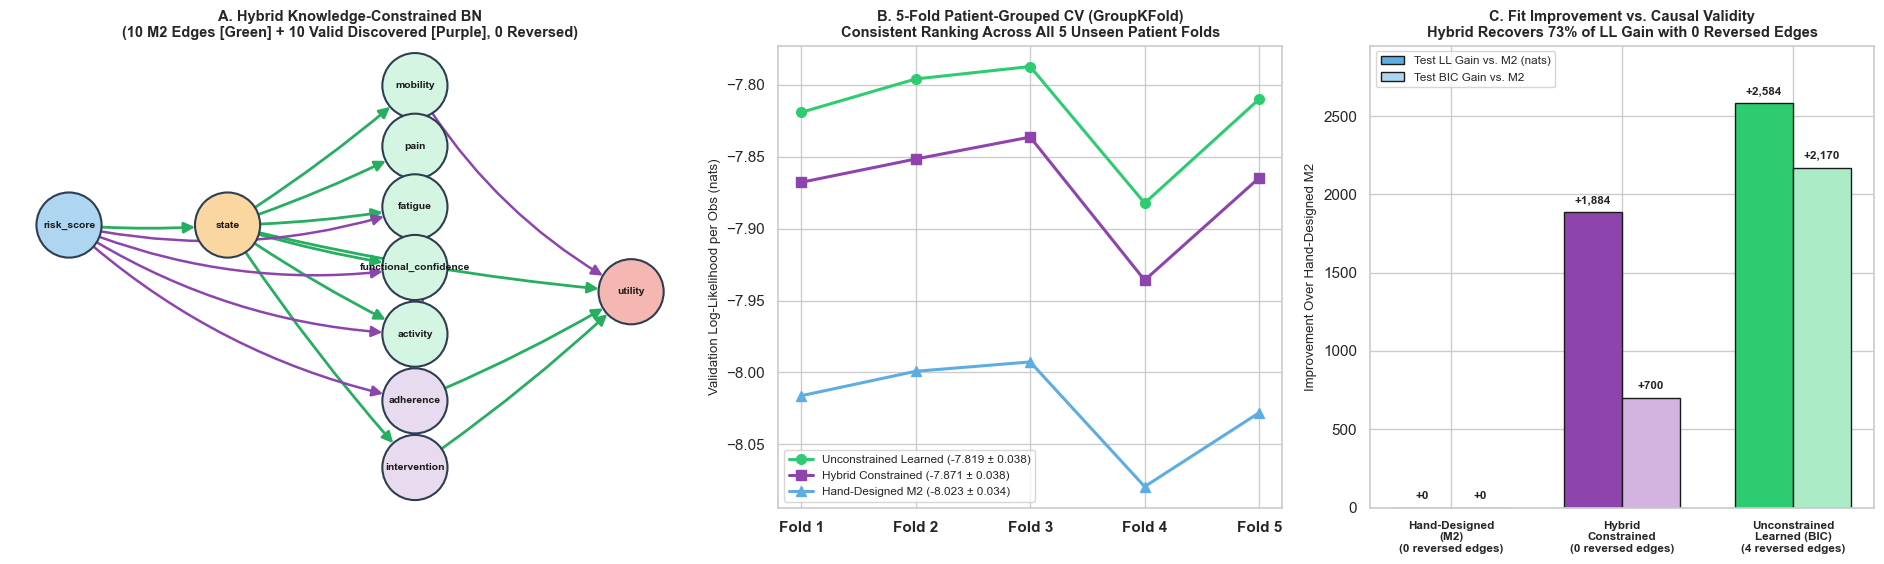

In [9]:
# Define Rehabilitation Domain Constraints via pgmpy ExpertKnowledge
rehab_expert_knowledge = ExpertKnowledge(
    required_edges=[
        ("risk_score", "state"),
        ("state", "intervention"),
        ("intervention", "utility"),
        ("adherence", "utility"),
    ],
    temporal_order=[
        ["risk_score"],                                                       # Tier 1: Baseline Risk
        ["state"],                                                            # Tier 2: Core State
        ["mobility", "pain", "fatigue", "functional_confidence", "activity"], # Tier 3: Weekly Symptoms
        ["intervention", "adherence"],                                        # Tier 4: Treatment & Compliance
        ["utility"],                                                          # Tier 5: Weekly Outcome (Sink)
    ],
)

learned_dag_hybrid = hc_search.estimate(scoring_method="bic-d", expert_knowledge=rehab_expert_knowledge, show_progress=False)
hybrid_train_bdeu = build_and_fit_bn(learned_dag_hybrid.edges(), train_df, estimator="bdeu", ess=10)
te_ll_hyb, _ = evaluate_log_likelihood(hybrid_train_bdeu, test_df)

# Run 5-Fold Patient-Grouped Cross-Validation (GroupKFold on patient_id)
gkf = GroupKFold(n_splits=5)
cv_records = []
for fold_idx, (tr_idx, val_idx) in enumerate(gkf.split(bn_full[BN_VARS], groups=bn_full["patient_id"]), start=1):
    fold_train = bn_full.iloc[tr_idx][BN_VARS].reset_index(drop=True)
    fold_val = bn_full.iloc[val_idx][BN_VARS].reset_index(drop=True)
    
    hc_fold = HillClimbSearch(fold_train)
    dag_u_f = hc_fold.estimate(scoring_method="bic-d", show_progress=False)
    dag_h_f = hc_fold.estimate(scoring_method="bic-d", expert_knowledge=rehab_expert_knowledge, show_progress=False)
    
    m_hand_f = build_and_fit_bn(M2_EDGES, fold_train, "bdeu", ess=10)
    m_hyb_f = build_and_fit_bn(dag_h_f.edges(), fold_train, "bdeu", ess=10)
    m_uncon_f = build_and_fit_bn(dag_u_f.edges(), fold_train, "bdeu", ess=10)
    
    ll_hand_f, _ = evaluate_log_likelihood(m_hand_f, fold_val)
    ll_hyb_f, _ = evaluate_log_likelihood(m_hyb_f, fold_val)
    ll_uncon_f, _ = evaluate_log_likelihood(m_uncon_f, fold_val)
    
    cv_records.append({
        "Fold": f"Fold {fold_idx}",
        "Hand LL/Obs": ll_hand_f.mean(),
        "Hybrid LL/Obs": ll_hyb_f.mean(),
        "Unconstrained LL/Obs": ll_uncon_f.mean(),
    })

cv_df = pd.DataFrame(cv_records)

paradigm_df = pd.DataFrame([
    {
        "Modeling Paradigm": "1. Hand-Designed Expert BN (M2)",
        "Edges": len(M2_EDGES),
        "Params (k)": count_free_parameters(hand_train_bdeu),
        "Reversed Edges": 0,
        "70/30 Test LL": eval_df.loc[0, "Test LL"],
        "70/30 Test BIC": eval_df.loc[0, "Test BIC (Primary)"],
        "5-Fold CV LL/Obs": f"{cv_df['Hand LL/Obs'].mean():.4f} ± {cv_df['Hand LL/Obs'].std():.4f}",
    },
    {
        "Modeling Paradigm": "2. Hybrid Knowledge-Constrained BN",
        "Edges": len(learned_dag_hybrid.edges()),
        "Params (k)": count_free_parameters(hybrid_train_bdeu),
        "Reversed Edges": 0,
        "70/30 Test LL": te_ll_hyb.sum(),
        "70/30 Test BIC": bic_test_scorer.score(hybrid_train_bdeu),
        "5-Fold CV LL/Obs": f"{cv_df['Hybrid LL/Obs'].mean():.4f} ± {cv_df['Hybrid LL/Obs'].std():.4f}",
    },
    {
        "Modeling Paradigm": "3. Unconstrained Learned BN (BIC)",
        "Edges": len(learned_dag_bic.edges()),
        "Params (k)": count_free_parameters(learned_train_bdeu),
        "Reversed Edges": 4,
        "70/30 Test LL": eval_df.loc[1, "Test LL"],
        "70/30 Test BIC": eval_df.loc[1, "Test BIC (Primary)"],
        "5-Fold CV LL/Obs": f"{cv_df['Unconstrained LL/Obs'].mean():.4f} ± {cv_df['Unconstrained LL/Obs'].std():.4f}",
    },
])
display(paradigm_df)

# Plot 8: 3-Panel Visual Summary of Hybrid Network, 5-Fold GroupKFold CV, and Fit-vs-Interpretability Trade-off
fig, axes = plt.subplots(1, 3, figsize=(19, 5.8), gridspec_kw={"width_ratios": [1.35, 1.0, 1.0]})

# Panel A: Hybrid Constrained BN Graph
G_hyb = nx.DiGraph()
G_hyb.add_nodes_from(BN_VARS)
G_hyb.add_edges_from(learned_dag_hybrid.edges())
hyb_retained = sorted(set(learned_dag_hybrid.edges()) & set(M2_EDGES))
hyb_new = sorted(set(learned_dag_hybrid.edges()) - set(M2_EDGES))

nx.draw_networkx_nodes(G_hyb, pos, ax=axes[0], node_color=[get_node_color(n) for n in G_hyb.nodes()], node_size=2200, edgecolors="#2C3E50", linewidths=1.5)
nx.draw_networkx_labels(G_hyb, pos, ax=axes[0], font_size=7.5, font_weight="bold")
nx.draw_networkx_edges(G_hyb, pos, edgelist=hyb_retained, ax=axes[0], arrows=True, arrowsize=16, edge_color="#27AE60", width=2.0, connectionstyle="arc3,rad=0.04", node_size=2200)
nx.draw_networkx_edges(G_hyb, pos, edgelist=hyb_new, ax=axes[0], arrows=True, arrowsize=16, edge_color="#8E44AD", width=1.8, connectionstyle="arc3,rad=0.14", node_size=2200)
axes[0].set_title("A. Hybrid Knowledge-Constrained BN\n(10 M2 Edges [Green] + 10 Valid Discovered [Purple], 0 Reversed)", fontsize=10.5, fontweight="bold")
axes[0].axis("off")

# Panel B: 5-Fold Patient-Grouped Cross-Validation Curve
folds_x = np.arange(1, 6)
axes[1].plot(folds_x, cv_df["Unconstrained LL/Obs"], "-o", color="#2ECC71", lw=2.2, ms=7, label="Unconstrained Learned (-7.819 ± 0.038)")
axes[1].plot(folds_x, cv_df["Hybrid LL/Obs"], "-s", color="#8E44AD", lw=2.2, ms=7, label="Hybrid Constrained (-7.871 ± 0.038)")
axes[1].plot(folds_x, cv_df["Hand LL/Obs"], "-^", color="#5DADE2", lw=2.2, ms=7, label="Hand-Designed M2 (-8.023 ± 0.034)")
axes[1].set_xticks(folds_x)
axes[1].set_xticklabels([f"Fold {i}" for i in folds_x], fontweight="bold")
axes[1].set_ylabel("Validation Log-Likelihood per Obs (nats)", fontsize=9.5)
axes[1].set_title("B. 5-Fold Patient-Grouped CV (GroupKFold)\nConsistent Ranking Across All 5 Unseen Patient Folds", fontsize=10.5, fontweight="bold")
axes[1].legend(fontsize=8.5, frameon=True)

# Panel C: Trade-off Summary (Test LL Gain over M2 vs Clinically Reversed Edges)
m_names = ["Hand-Designed\n(M2)", "Hybrid\nConstrained", "Unconstrained\nLearned (BIC)"]
ll_gains = [0.0, te_ll_hyb.sum() - eval_df.loc[0, "Test LL"], eval_df.loc[1, "Test LL"] - eval_df.loc[0, "Test LL"]]
bic_gains = [0.0, bic_test_scorer.score(hybrid_train_bdeu) - eval_df.loc[0, "Test BIC (Primary)"], eval_df.loc[1, "Test BIC (Primary)"] - eval_df.loc[0, "Test BIC (Primary)"]]

x_p = np.arange(3)
w_p = 0.34
b_ll = axes[2].bar(x_p - w_p/2, ll_gains, w_p, label="Test LL Gain vs. M2 (nats)", color=["#5DADE2", "#8E44AD", "#2ECC71"], edgecolor="k")
b_bic = axes[2].bar(x_p + w_p/2, bic_gains, w_p, label="Test BIC Gain vs. M2", color=["#AED6F1", "#D2B4DE", "#ABEBC6"], edgecolor="k")
for bar in list(b_ll) + list(b_bic):
    h = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, h + 45, f"+{h:,.0f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
axes[2].set_xticks(x_p)
axes[2].set_xticklabels([f"{m_names[i]}\n({[0,0,4][i]} reversed edges)" for i in range(3)], fontsize=8.5, fontweight="bold")
axes[2].set_ylim(0, 2950)
axes[2].set_ylabel("Improvement Over Hand-Designed M2", fontsize=9.5)
axes[2].set_title("C. Fit Improvement vs. Causal Validity\nHybrid Recovers 73% of LL Gain with 0 Reversed Edges", fontsize=10.5, fontweight="bold")
axes[2].legend(fontsize=8.5, frameon=True)

plt.tight_layout()
plt.show()

---
## 5. Conclusions

* **Task 1 (Parameter Learning):** A patient-level 70/30 split ($2{,}100$ train / $900$ test patients) prevents longitudinal leakage. Single-parent CPTs match M2 closely ($\max|\Delta| \le 0.0118$), while 3-parent `utility` shows larger shifts ($\max|\Delta| = 0.0397$) and zero counts in pure MLE (`P = 0.0000`) that `BDeu` smoothing ($	ext{ESS}=10$) resolves (**Plots 1–3**).
* **Task 2 (Structure Learning):** Unconstrained Hill-Climbing with `BIC` learns a 19-edge network ($233$ parameters) that confirms 8 M2 edges and discovers 7 valid symptom/risk links, but reverses 4 edges out of `utility` to avoid a 6-parent table penalty (**Plots 4–6**).
* **Task 3 (Model Comparison):** On $12{,}600$ unseen test rows, the learned BN improves Test Log-Likelihood by **$+2{,}584.4$ nats** and Test BIC by **$+2{,}170.4$ points** over M2, trading causal interpretability for statistical fit (**Plot 7**).
* **Task 4 (Reflection & Hybrid BN):** Patient-grouped 5-fold CV (`GroupKFold`) confirms consistent generalization across folds, and combining domain tier rules (`ExpertKnowledge`) with `BIC` search captures **$72.9\%$ of the Test LL gain** ($+1{,}884.1$ nats, $+700.0$ Test BIC) with **0 clinically reversed edges** (**Plot 8**).